In [1]:
# Project path setup: works whether Jupyter was launched from the project root or notebooks/.
from pathlib import Path
import os
cwd = Path.cwd()
if (cwd / "data").is_dir() and (cwd / "notebooks").is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data").is_dir() and cwd.name == "notebooks":
    PROJECT_ROOT = cwd.parent
else:
    raise RuntimeError("Open this notebook from the project root or its notebooks/ folder.")
os.chdir(PROJECT_ROOT / "notebooks")
print("Project root:", PROJECT_ROOT)
print("Notebook working directory:", Path.cwd())

Project root: /home/akshat/Desktop/main files (i think)/ml course work/ml project
Notebook working directory: /home/akshat/Desktop/main files (i think)/ml course work/ml project/notebooks


# 09 — LinearSVC Vocabulary-Size Experiment

This is a deployment-size experiment for a compact LinearSVC alternative. It does not replace the project’s selected Logistic Regression model.

Only `max_features` varies across 5,000, 10,000, 25,000 and 50,000 limits. Primary metric: 5-fold stratified CV Macro F1. The test set is not used for selecting a vocabulary size.

In [2]:
import json
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import make_scorer, f1_score

RANDOM_STATE = 42
N_JOBS = 3
PRE_DISPATCH = 3

FEATURE_LIMITS = [5000, 10000, 25000, 50000]

# Fixed model settings: do not change these between feature-limit runs.
TFIDF_FIXED = {
    "stop_words": None,
    "ngram_range": (1, 2),
    "min_df": 10,
    "max_df": 1.0,
    "sublinear_tf": True,
    "lowercase": True,
    "norm": "l2",
    "use_idf": True,
    "smooth_idf": True,
    "token_pattern": r"(?u)\b\w\w+\b",
}

SVC_FIXED = {
    "C": 1.0,
    "class_weight": None,
    "max_iter": 10000,
    "random_state": RANDOM_STATE,
}

CV = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

SCORING = {
    "macro_f1": "f1_macro",
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
}

## 1. Load the same processed training split

This experiment expects the same processed training data used by your project notebooks: `data/processed/train.csv`, with columns `text` and `target` (OR=0, CG=1).

The path resolver supports running this notebook from either the project root or the `notebooks/` directory.

In [3]:
possible_train_paths = [
    Path("../data/processed/train.csv"),  # notebook opened with notebooks/ as cwd
    Path("data/processed/train.csv"),     # project root as cwd
]

TRAIN_PATH = next((p.resolve() for p in possible_train_paths if p.exists()), None)
if TRAIN_PATH is None:
    raise FileNotFoundError(
        "Could not find data/processed/train.csv. "
        "Run this notebook from the project root or notebooks/ directory."
    )

train_df = pd.read_csv(TRAIN_PATH)

required_columns = {"text", "target"}
missing_columns = required_columns - set(train_df.columns)
if missing_columns:
    raise ValueError(f"Training CSV is missing columns: {sorted(missing_columns)}")

if train_df["text"].isna().any() or train_df["target"].isna().any():
    raise ValueError("Missing text or target values found. Resolve them before running CV.")

X_train = train_df["text"].astype(str).str.strip()
y_train = train_df["target"].astype(int)

if set(y_train.unique()) != {0, 1}:
    raise ValueError(f"Expected binary labels 0 and 1; found {sorted(y_train.unique())}")

print("Training rows:", len(train_df))
print("Label distribution:")
print(y_train.value_counts().sort_index())
print("Training data:", TRAIN_PATH)

Training rows: 32328
Label distribution:
target
0    16172
1    16156
Name: count, dtype: int64
Training data: /home/akshat/Desktop/main files (i think)/ml course work/ml project/data/processed/train.csv


## 2. Define the pipeline and browser-export payload

The LinearSVC browser payload contains the vocabulary, IDF values, coefficient vector and intercept. Its JSON size is measured after serialisation using the same core information needed for browser-side TF-IDF and decision-score inference.

LinearSVC does **not** natively output calibrated probabilities. The browser should display a decision margin or label, not call the margin a probability.

In [4]:
def build_pipeline(max_features: int) -> Pipeline:
    tfidf_params = dict(TFIDF_FIXED)
    tfidf_params["max_features"] = max_features

    return Pipeline([
        ("tfidf", TfidfVectorizer(**tfidf_params)),
        ("classifier", LinearSVC(**SVC_FIXED)),
    ])


def make_browser_payload(fitted_pipeline: Pipeline) -> dict:
    vectorizer = fitted_pipeline.named_steps["tfidf"]
    classifier = fitted_pipeline.named_steps["classifier"]

    return {
        "model_type": "TF-IDF + LinearSVC",
        "model_family": "linearsvc",
        "classes": [int(x) for x in classifier.classes_],
        "positive_class": 1,
        "intercept": float(classifier.intercept_[0]),
        "vocabulary": {
            str(term): int(index)
            for term, index in vectorizer.vocabulary_.items()
        },
        "idf": [float(x) for x in vectorizer.idf_],
        "coefficients": [float(x) for x in classifier.coef_[0]],
        "score_description": (
            "LinearSVC decision margin; positive values favour CG (class 1). "
            "This is not a probability."
        ),
        "vectorizer": {
            "lowercase": bool(vectorizer.lowercase),
            "ngram_range": [int(x) for x in vectorizer.ngram_range],
            "min_df": int(vectorizer.min_df),
            "max_df": float(vectorizer.max_df),
            "max_features": int(vectorizer.max_features),
            "stop_words": None,
            "sublinear_tf": bool(vectorizer.sublinear_tf),
            "norm": vectorizer.norm,
            "use_idf": bool(vectorizer.use_idf),
            "smooth_idf": bool(vectorizer.smooth_idf),
            "token_pattern": vectorizer.token_pattern,
        },
    }

## 3. Run controlled five-fold cross-validation

For each vocabulary limit, the TF-IDF vectorizer is fitted inside the pipeline separately on each fold's training partition. This avoids vocabulary/IDF leakage across folds.

`return_train_score=True` records the training-fold score. The generalisation gap is calculated as:

`mean_train_macro_f1 - mean_validation_macro_f1`

A smaller gap is not automatically better: it must be considered alongside validation Macro F1.

In [5]:
rows = []
fitted_models = {}

for max_features in FEATURE_LIMITS:
    print("=" * 72)
    print(f"Running LinearSVC with max_features={max_features:,}")
    start = time.time()

    pipeline = build_pipeline(max_features)

    cv_output = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=CV,
        scoring=SCORING,
        return_train_score=True,
        n_jobs=N_JOBS,
        pre_dispatch=PRE_DISPATCH,
        error_score="raise",
    )

    elapsed = time.time() - start

    train_macro_f1 = float(np.mean(cv_output["train_macro_f1"]))
    validation_macro_f1 = float(np.mean(cv_output["test_macro_f1"]))
    gap = train_macro_f1 - validation_macro_f1
    validation_std = float(np.std(cv_output["test_macro_f1"], ddof=1))

    rows.append({
        "max_features_limit": max_features,
        "mean_train_macro_f1": train_macro_f1,
        "mean_cv_macro_f1": validation_macro_f1,
        "generalization_gap": gap,
        "std_cv_macro_f1": validation_std,
        "mean_cv_accuracy": float(np.mean(cv_output["test_accuracy"])),
        "mean_cv_balanced_accuracy": float(np.mean(cv_output["test_balanced_accuracy"])),
        "cv_fold_scores": [float(x) for x in cv_output["test_macro_f1"]],
        "cv_time_seconds": elapsed,
    })

    print(f"Train Macro F1: {train_macro_f1:.4%}")
    print(f"CV Macro F1:    {validation_macro_f1:.4%}")
    print(f"Gap:            {gap:.4%}")
    print(f"CV std:         {validation_std:.4%}")
    print(f"Time:           {elapsed:.1f} seconds")

cv_results = pd.DataFrame(rows)
display(cv_results)

Running LinearSVC with max_features=5,000
Train Macro F1: 97.7372%
CV Macro F1:    93.4050%
Gap:            4.3322%
CV std:         0.2148%
Time:           8.0 seconds
Running LinearSVC with max_features=10,000
Train Macro F1: 98.9753%
CV Macro F1:    93.9185%
Gap:            5.0568%
CV std:         0.0910%
Time:           7.4 seconds
Running LinearSVC with max_features=25,000
Train Macro F1: 99.6520%
CV Macro F1:    94.3793%
Gap:            5.2727%
CV std:         0.1802%
Time:           7.6 seconds
Running LinearSVC with max_features=50,000
Train Macro F1: 99.6520%
CV Macro F1:    94.3793%
Gap:            5.2727%
CV std:         0.1802%
Time:           7.5 seconds


,max_features_limit,mean_train_macro_f1,mean_cv_macro_f1,generalization_gap,std_cv_macro_f1,mean_cv_accuracy,mean_cv_balanced_accuracy,cv_fold_scores,cv_time_seconds
0,5000,0.977372,0.934050,0.043322,0.002148,0.934051,0.934050,"[0.9370553288945422, 0.9351963663806541, 0.932...",8.009577
1,10000,0.989753,0.939185,0.050568,0.000910,0.939186,0.939185,"[0.9396844977865133, 0.9376721608156118, 0.939...",7.421940
2,25000,0.996520,0.943793,0.052727,0.001802,0.943795,0.943793,"[0.9447875401097594, 0.9437021702955626, 0.945...",7.564229
3,50000,0.996520,0.943793,0.052727,0.001802,0.943795,0.943793,"[0.9447875401097594, 0.9437021702955626, 0.945...",7.524301


## 4. Fit each configuration on all training data and measure export size

This step does not evaluate on the test set. It fits each candidate on the full training split to measure its actual learned vocabulary size and browser JSON payload size.

The serialized JSON size is a useful estimate of the model data downloaded by the website. Actual page-load time also depends on network speed, compression, parsing and browser implementation.

In [6]:
PROJECT_ROOT = TRAIN_PATH.parent.parent.parent
OUTPUT_DIR = PROJECT_ROOT / "results" / "linearsvc_vocab_experiment"
MODEL_DIR = PROJECT_ROOT / "models" / "linearsvc_vocab_experiment"
JSON_DIR = PROJECT_ROOT / "results" / "linearsvc_vocab_experiment" / "browser_payloads"

for directory in (OUTPUT_DIR, MODEL_DIR, JSON_DIR):
    directory.mkdir(parents=True, exist_ok=True)

export_rows = []

for max_features in FEATURE_LIMITS:
    print(f"Fitting full training data: {max_features:,} features")
    fitted = build_pipeline(max_features)
    fitted.fit(X_train, y_train)

    vectorizer = fitted.named_steps["tfidf"]
    actual_vocab_size = len(vectorizer.vocabulary_)

    model_path = MODEL_DIR / f"linearsvc_{max_features}.joblib"
    json_path = JSON_DIR / f"linearsvc_{max_features}.json"

    joblib.dump(fitted, model_path)

    payload = make_browser_payload(fitted)
    json_text = json.dumps(payload, separators=(",", ":"), ensure_ascii=False)
    json_path.write_text(json_text, encoding="utf-8")

    json_size_bytes = json_path.stat().st_size
    json_size_mb = json_size_bytes / (1024 * 1024)

    export_rows.append({
        "max_features_limit": max_features,
        "actual_vocabulary_size": actual_vocab_size,
        "browser_json_bytes": json_size_bytes,
        "browser_json_mb": json_size_mb,
        "pipeline_joblib_mb": model_path.stat().st_size / (1024 * 1024),
        "browser_json_path": str(json_path),
        "pipeline_path": str(model_path),
    })

    print(f"Actual vocabulary: {actual_vocab_size:,}")
    print(f"Browser JSON: {json_size_mb:.3f} MB")

export_results = pd.DataFrame(export_rows)
final_results = cv_results.merge(export_results, on="max_features_limit")
display(final_results)

Fitting full training data: 5,000 features
Actual vocabulary: 5,000
Browser JSON: 0.253 MB
Fitting full training data: 10,000 features
Actual vocabulary: 10,000
Browser JSON: 0.513 MB
Fitting full training data: 25,000 features
Actual vocabulary: 25,000
Browser JSON: 1.319 MB
Fitting full training data: 50,000 features
Actual vocabulary: 27,293
Browser JSON: 1.444 MB


,max_features_limit,mean_train_macro_f1,mean_cv_macro_f1,generalization_gap,std_cv_macro_f1,mean_cv_accuracy,mean_cv_balanced_accuracy,cv_fold_scores,cv_time_seconds,actual_vocabulary_size,browser_json_bytes,browser_json_mb,pipeline_joblib_mb,browser_json_path,pipeline_path
0,5000,0.977372,0.934050,0.043322,0.002148,0.934051,0.934050,"[0.9370553288945422, 0.9351963663806541, 0.932...",8.009577,5000,265557,0.253255,0.218323,/home/akshat/Desktop/main files (i think)/ml c...,/home/akshat/Desktop/main files (i think)/ml c...
1,10000,0.989753,0.939185,0.050568,0.000910,0.939186,0.939185,"[0.9396844977865133, 0.9376721608156118, 0.939...",7.421940,10000,538019,0.513095,0.439972,/home/akshat/Desktop/main files (i think)/ml c...,/home/akshat/Desktop/main files (i think)/ml c...
2,25000,0.996520,0.943793,0.052727,0.001802,0.943795,0.943793,"[0.9447875401097594, 0.9437021702955626, 0.945...",7.564229,25000,1382593,1.318543,1.113220,/home/akshat/Desktop/main files (i think)/ml c...,/home/akshat/Desktop/main files (i think)/ml c...
3,50000,0.996520,0.943793,0.052727,0.001802,0.943795,0.943793,"[0.9447875401097594, 0.9437021702955626, 0.945...",7.524301,27293,1513882,1.443750,1.217331,/home/akshat/Desktop/main files (i think)/ml c...,/home/akshat/Desktop/main files (i think)/ml c...


## 5. Save the comparison table and plots

The table is the primary artifact to use when deciding which vocabulary size to retain.

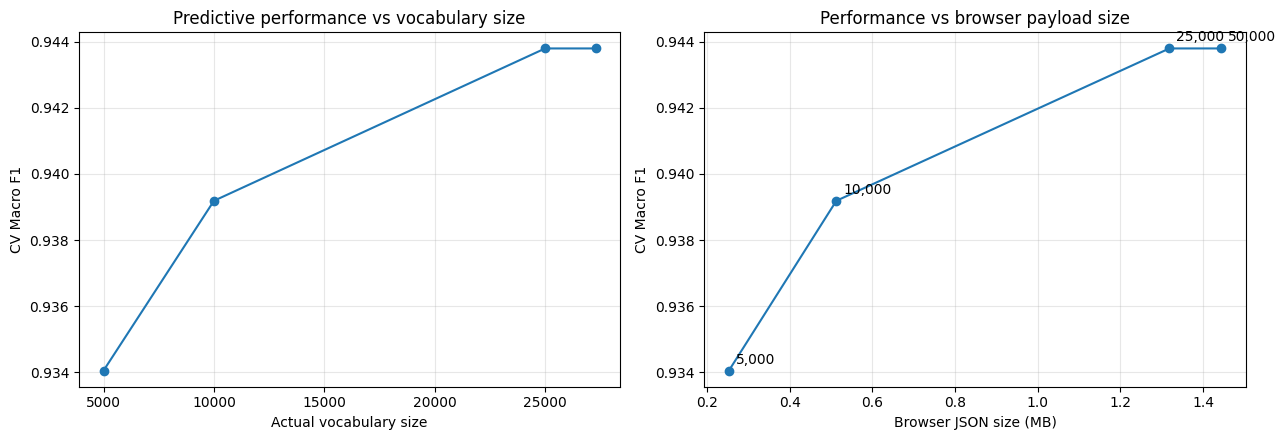

Saved: /home/akshat/Desktop/main files (i think)/ml course work/ml project/results/linearsvc_vocab_experiment/linearsvc_vocabulary_comparison.csv
Saved: /home/akshat/Desktop/main files (i think)/ml course work/ml project/results/linearsvc_vocab_experiment/linearsvc_vocabulary_comparison.json
Saved: /home/akshat/Desktop/main files (i think)/ml course work/ml project/results/linearsvc_vocab_experiment/linearsvc_vocabulary_tradeoff.png


In [7]:
csv_path = OUTPUT_DIR / "linearsvc_vocabulary_comparison.csv"
json_path = OUTPUT_DIR / "linearsvc_vocabulary_comparison.json"

final_results.to_csv(csv_path, index=False)
final_results.to_json(json_path, orient="records", indent=2)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(
    final_results["actual_vocabulary_size"],
    final_results["mean_cv_macro_f1"],
    marker="o",
    label="CV Macro F1",
)
axes[0].set_xlabel("Actual vocabulary size")
axes[0].set_ylabel("CV Macro F1")
axes[0].set_title("Predictive performance vs vocabulary size")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    final_results["browser_json_mb"],
    final_results["mean_cv_macro_f1"],
    marker="o",
)
for _, row in final_results.iterrows():
    axes[1].annotate(
        f'{int(row["max_features_limit"]):,}',
        (row["browser_json_mb"], row["mean_cv_macro_f1"]),
        xytext=(5, 5),
        textcoords="offset points",
    )
axes[1].set_xlabel("Browser JSON size (MB)")
axes[1].set_ylabel("CV Macro F1")
axes[1].set_title("Performance vs browser payload size")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
figure_path = OUTPUT_DIR / "linearsvc_vocabulary_tradeoff.png"
plt.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()

print("Saved:", csv_path)
print("Saved:", json_path)
print("Saved:", figure_path)

## 6. Select a compact candidate using CV only

This is a decision aid, not an automatic final-model selector. It identifies the smallest vocabulary whose mean CV Macro F1 is within 0.5 percentage points of the best observed CV Macro F1.

Inspect fold scores and standard deviations before deciding. If two candidates are very close relative to fold-to-fold variation, prefer the smaller payload only if the performance trade-off is acceptable for the website.

In [8]:
best_cv = final_results["mean_cv_macro_f1"].max()
tolerance = 0.005  # 0.5 percentage points

eligible = final_results[
    final_results["mean_cv_macro_f1"] >= best_cv - tolerance
].sort_values("actual_vocabulary_size")

print(f"Best observed CV Macro F1: {best_cv:.4%}")
print(f"Within tolerance: {tolerance:.2%}")

if len(eligible):
    suggested = eligible.iloc[0]
    print("\nSmallest candidate within 0.5 percentage points of the best:")
    print(f'Max feature limit: {int(suggested["max_features_limit"]):,}')
    print(f'Actual vocabulary: {int(suggested["actual_vocabulary_size"]):,}')
    print(f'CV Macro F1: {suggested["mean_cv_macro_f1"]:.4%}')
    print(f'Generalisation gap: {suggested["generalization_gap"]:.4%}')
    print(f'Browser JSON: {suggested["browser_json_mb"]:.3f} MB')
else:
    print("No candidate met the tolerance rule.")

print("\nDo not use the test set to choose the vocabulary limit.")

Best observed CV Macro F1: 94.3793%
Within tolerance: 0.50%

Smallest candidate within 0.5 percentage points of the best:
Max feature limit: 10,000
Actual vocabulary: 10,000
CV Macro F1: 93.9185%
Generalisation gap: 5.0568%
Browser JSON: 0.513 MB

Do not use the test set to choose the vocabulary limit.


## Interpretation checklist

Before choosing the website model, answer these questions:

1. How much CV Macro F1 is lost when reducing from 50,000 to 10,000 features?
2. Does the CV standard deviation suggest that the difference is meaningful?
3. Does the smaller vocabulary reduce browser JSON size enough to matter?
4. Is the generalisation gap improving, or is the model simply underfitting?
5. Does the selected model's browser implementation reproduce Python decision scores on the same test examples?

**Important:** this notebook compares vocabulary sizes for LinearSVC only. It does not compare LinearSVC against Logistic Regression under the same vocabulary-size experiment. Your current Logistic Regression remains the project's selected model unless you deliberately change that decision after reviewing these results.